# Human PBMCs

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2026-01-18
> - Modified: 2026-01-18
---

> - [10k Human PBMCs, 3' v3.1, Chromium X](https://www.10xgenomics.com/datasets/20-k-human-pbm-cs-3-ht-v-3-1-chromium-x-3-1-high-6-1-0)
> - Organism: Homo sapiens
> - Tissue: PBMCs
> - 10X Universal 3' V3.1 scRNA-seq
> - 2021-08-09
---

# Experimental Design

> - Chromium Next GEM Single Cell 3' HT Reagent Kits v3.1 User Guide (CG000416 Rev A)
> - Chromium X Series
>     - input: ~33,000 cells
>     - recovered: 23,837 cells
> - Illumina NovaSeq 6000
> - Cell Ranger v6.1.0 with --expect-cells = 20000

| Sample | Tissue | Full name | Gender | Age | Disease status |
| - | - | - | - | - | - |
| Donor | PBMCs | Peripheral blood mononuclear cells | Female | 25-30 | Healthy |

---

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [2]:
data_dir <- "~/data1/single_cell_dataset/dataset_10xGenomics/Hs_PBMCs_3Pv3_20k"

In [3]:
dir.create(file.path(data_dir, "result"), 
           recursive = TRUE, showWarnings = FALSE)
# dir.create(file.path(data_dir, "visualization"), 
#            recursive = TRUE, showWarnings = FALSE)

In [4]:
scrna <- file.path(
    data_dir, "matrix", "filtered_feature_bc_matrix.h5") |> 
    Read10X_h5() |>
    CreateSeuratObject(project = "PBMCs", min.cells = 3)

In [5]:
scrna

An object of class Seurat 
24018 features across 23837 samples within 1 assay 
Active assay: RNA (24018 features, 0 variable features)
 1 layer present: counts

# 2. Quality Control

## 1). Calculate Metrics

In [6]:
# Mitochondrial genes
mt <- "(?i)^MT-"
scrna <- PercentageFeatureSet(
    scrna, pattern = mt, col.name = "percent.mt")

In [7]:
# Ribosomal genes
rp <- "(?i)^(MRP|RP[LS])"
scrna <- PercentageFeatureSet(
    scrna, pattern = rp, col.name = "percent.rp")

In [8]:
# Hemoglobin genes
hb <- "^(HBA1|HBA2|HBAP1|HBB|HBBP1|HBD|HBE1|HBG1|HBG2|HBM|HBQ1|HBZ|HBZP1)"
scrna <- PercentageFeatureSet(
    scrna, pattern = hb, col.name = "percent.hb")

## 2). Visualizate Metrics

In [9]:
source("R/run_seurat_pipeline.R")

In [10]:
sc.temp <- run_seurat_pipeline(scrna, ndim = 20)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”


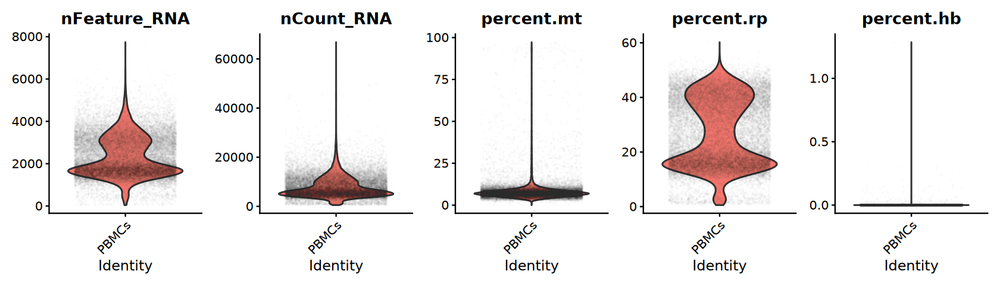

In [11]:
options(repr.plot.width = 14, repr.plot.height = 4)
VlnPlot(sc.temp, layer = "counts", group.by = "orig.ident",
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                     "percent.rp", "percent.hb"), 
        pt.size = 0.01, alpha = 0.01, ncol = 5) & NoLegend()

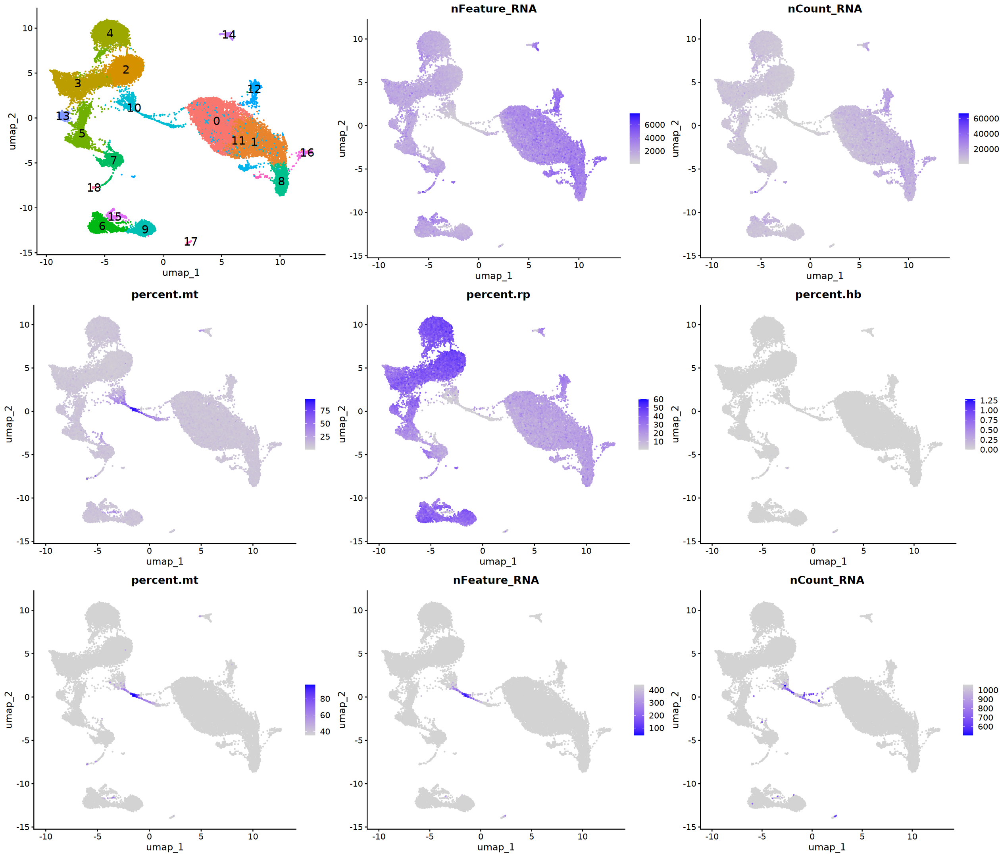

In [12]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                 "percent.rp", "percent.hb"))
p3 <- FeaturePlot(
    sc.temp, reduction = "umap", features = "percent.mt",
    min.cutoff = "q99", order = TRUE, combine = FALSE)
p4 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"),
    max.cutoff = "q1", cols = c("blue", "lightgrey"))

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3)

In [13]:
source("R/calculate_mad_threshold.R")

In [14]:
cat(sprintf("Counts: Lower: %d\n", calculate_mad_threshold(
    sc.temp$nCount_RNA, nmads = 3, sides = "lower")))

cat(sprintf("Features: Lower: %d\n", calculate_mad_threshold(
    sc.temp$nFeature_RNA, nmads = 3, sides = "lower")))

cat(sprintf("Mitochondrial: Upper: %d\n", calculate_mad_threshold(
    sc.temp$percent.mt, nmads = 3, sides = "upper")))

Counts: Lower: 1332
Features: Lower: 494
Mitochondrial: Upper: 17


## 3). Filtering Low-quality Cells

In [15]:
scrna <- subset(
    scrna, 
    subset = nFeature_RNA > 500 & percent.mt < 20)
scrna

An object of class Seurat 
24018 features across 23196 samples within 1 assay 
Active assay: RNA (24018 features, 0 variable features)
 1 layer present: counts

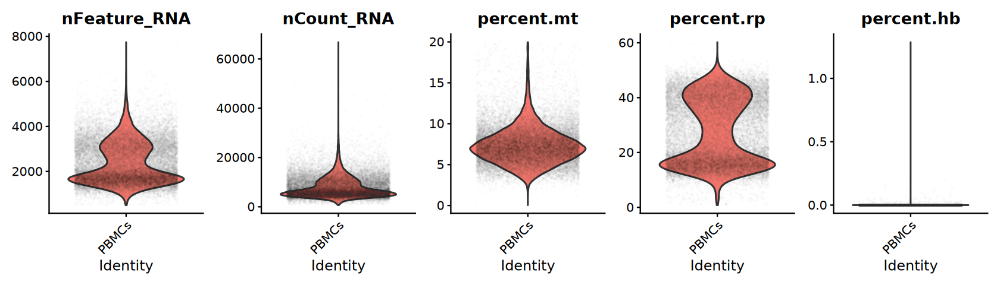

In [16]:
options(repr.plot.width = 14, repr.plot.height = 4)
VlnPlot(scrna, layer = "counts", group.by = "orig.ident",
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                     "percent.rp", "percent.hb"), 
        pt.size = 0.01, alpha = 0.01, ncol = 5) & NoLegend()

## 4). Doublet Detection

### a). [DoubletFinder](https://github.com/chris-mcginnis-ucsf/DoubletFinder)

In [17]:
source("R/run_DoubletFinder.R")

In [18]:
scrna <- run_DoubletFinder(
    scrna, ndim = 20, clusters = "seurat_clusters", 
    multiplet.rate = 0.008, seed = 123)

[1] "Creating 7732 artificial doublets..."
[1] "Classifying doublets.."


DoubletFinder completed: pN = 0.25, pK = 0.02, nExp_adj = 3885



In [19]:
table(scrna$DoubletFinder.class)


Singlet Doublet 
  19311    3885 

### b). [scDblFinder](https://github.com/plger/scDblFinder)

In [20]:
suppressPackageStartupMessages(library(scDblFinder))

In [21]:
set.seed(123)
sce <- run_seurat_pipeline(scrna, ndim = 20) |>
    as.SingleCellExperiment() |>
    scDblFinder(clusters = "seurat_clusters", verbose = FALSE)

In [22]:
scrna$scDblFinder.score <- colData(sce)$scDblFinder.score
scrna$scDblFinder.class <- colData(sce)$scDblFinder.class

In [23]:
table(scrna$scDblFinder.class)


singlet doublet 
  21133    2063 

### Filtering Doublets

In [24]:
sc.temp <- run_seurat_pipeline(scrna, ndim = 20)

In [25]:
table(scDblFinder = sc.temp$scDblFinder.class, 
      DoubletFinder = sc.temp$DoubletFinder.class)

           DoubletFinder
scDblFinder Singlet Doublet
    singlet   19095    2038
    doublet     216    1847

In [26]:
sc.temp$isDoublet <- apply(
    sc.temp@meta.data[, c(
        "scDblFinder.class", "DoubletFinder.class")],
    1, function(x) paste(x, collapse = "_")
    ) |> as.factor()

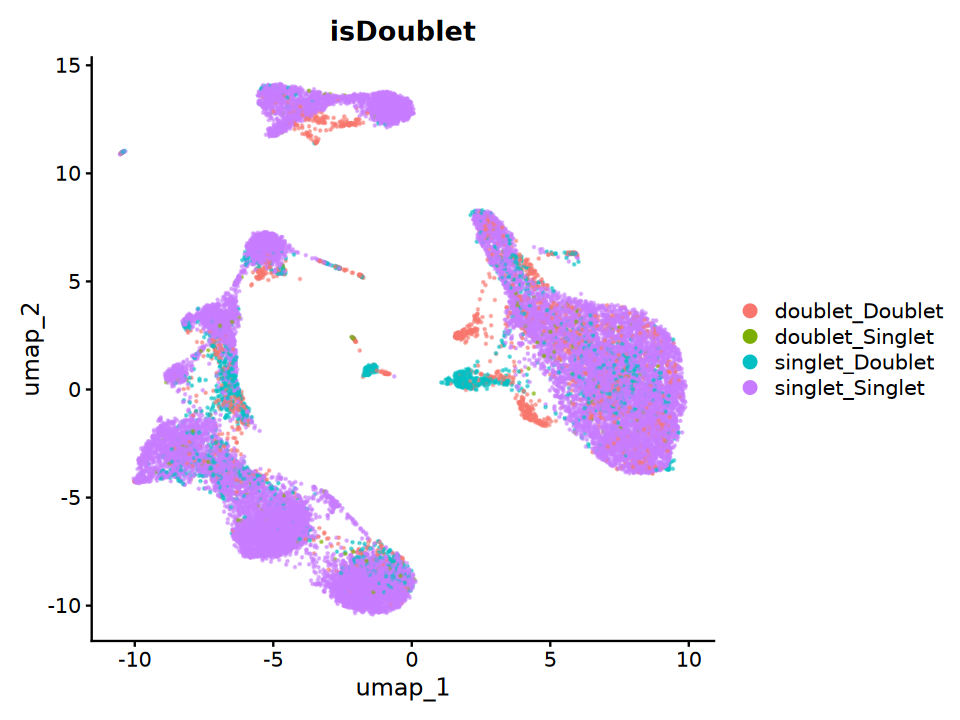

In [27]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(sc.temp, reduction = "umap",
        group.by = "isDoublet", 
        pt.size = 0.1, alpha = 0.5)

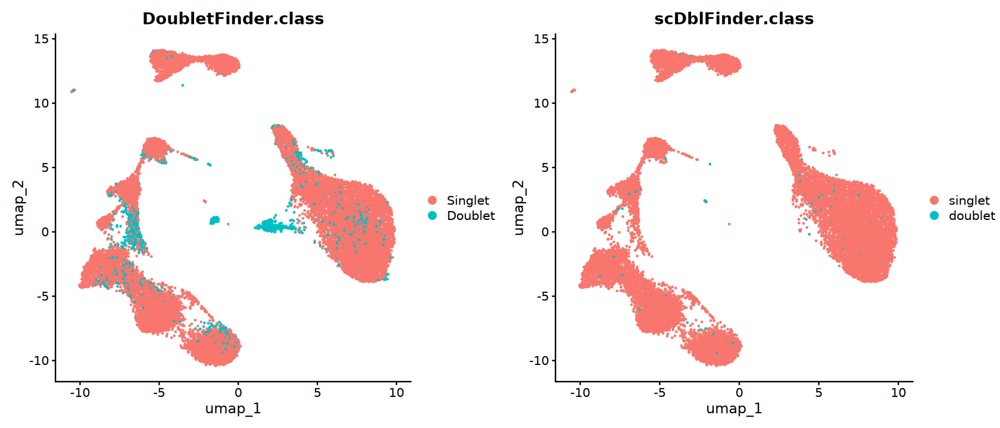

In [28]:
p1 <- DimPlot(
    subset(sc.temp, subset = scDblFinder.class == "singlet"),
    reduction = "umap", group.by = "DoubletFinder.class")
p2 <- DimPlot(
    subset(sc.temp, subset = DoubletFinder.class == "Singlet"), 
    reduction = "umap", group.by = "scDblFinder.class")

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [29]:
sc.temp <- subset(
    sc.temp, 
    subset = DoubletFinder.class == "Singlet" |
        scDblFinder.class == "singlet")
sc.temp

An object of class Seurat 
24018 features across 21349 samples within 1 assay 
Active assay: RNA (24018 features, 2000 variable features)
 3 layers present: counts, data, scale.data
 3 dimensional reductions calculated: pca, umap, tsne

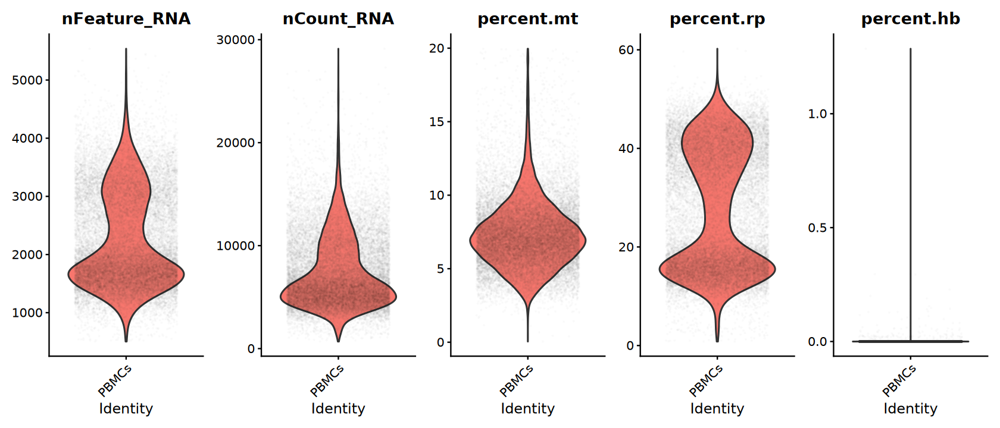

In [30]:
options(repr.plot.width = 14, repr.plot.height = 6)
VlnPlot(sc.temp, layer = "counts", group.by = "orig.ident",
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                     "percent.rp", "percent.hb"), 
        pt.size = 0.01, alpha = 0.01, ncol = 5) & NoLegend()

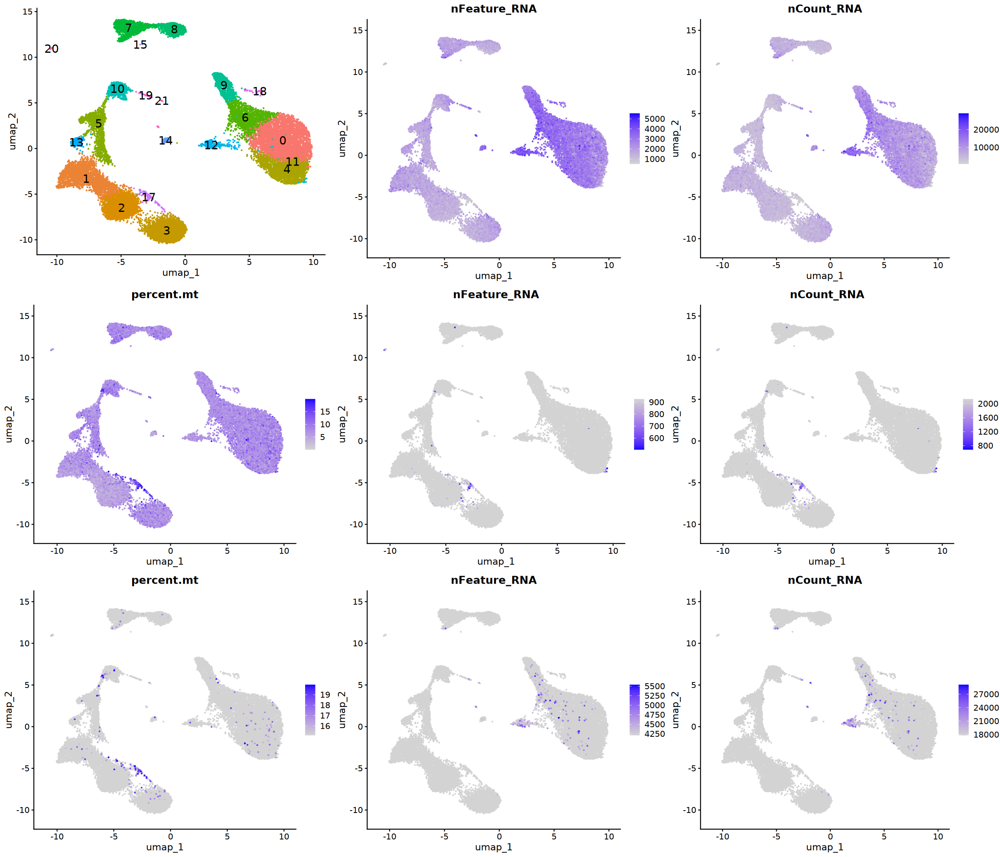

In [31]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt"))
p3 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"),
    max.cutoff = "q1", cols = c("blue", "lightgrey"))
p4 <- FeaturePlot(
    sc.temp, reduction = "umap",
    features = c("percent.mt", "nFeature_RNA", "nCount_RNA"),
    min.cutoff = "q99", order = TRUE, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3, byrow = TRUE)

In [32]:
summary(sc.temp@meta.data[, c("nFeature_RNA", "nCount_RNA", "percent.mt")])

  nFeature_RNA    nCount_RNA      percent.mt      
 Min.   : 504   Min.   :  687   Min.   : 0.04785  
 1st Qu.:1586   1st Qu.: 4822   1st Qu.: 5.79738  
 Median :1961   Median : 6322   Median : 7.09590  
 Mean   :2231   Mean   : 7333   Mean   : 7.33441  
 3rd Qu.:2918   3rd Qu.: 9353   3rd Qu.: 8.50719  
 Max.   :5538   Max.   :29120   Max.   :19.96060  

In [33]:
cat(sprintf("Counts: Upper: %d\n", calculate_mad_threshold(
    sc.temp$nCount_RNA, nmads = 3, sides = "upper")))

cat(sprintf("Features: Upper: %d\n", calculate_mad_threshold(
    sc.temp$nFeature_RNA, nmads = 3, sides = "upper")))

Counts: Upper: 26158
Features: Upper: 7002


In [34]:
scrna <- scrna |>
    subset(
        subset = DoubletFinder.class == "Singlet" |
            scDblFinder.class == "singlet") |>
    subset(
        subset = nCount_RNA < 25000 & 
            percent.mt < 20 & percent.hb < 1)
scrna

An object of class Seurat 
24018 features across 21334 samples within 1 assay 
Active assay: RNA (24018 features, 0 variable features)
 1 layer present: counts

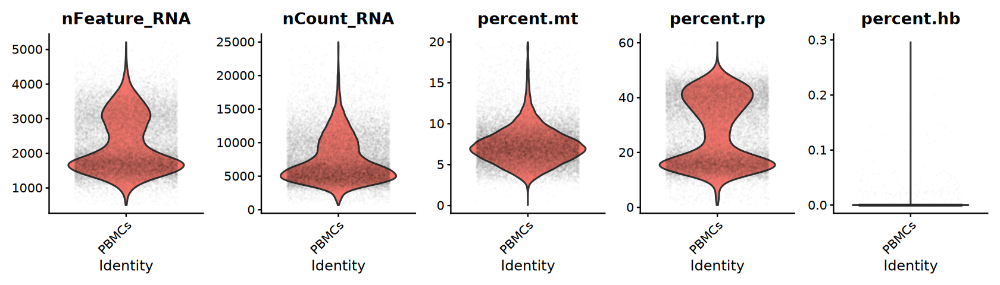

In [35]:
options(repr.plot.width = 14, repr.plot.height = 4)
VlnPlot(scrna, layer = "counts", group.by = "orig.ident",
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt",
                     "percent.rp", "percent.hb"), 
        pt.size = 0.01, alpha = 0.01, ncol = 5) & NoLegend()

## 5). Evaluating Noise

### a). Cell cycle effect

In [36]:
scrna <- NormalizeData(scrna, verbose = FALSE) |> 
    CellCycleScoring(s.features = cc.genes$s.genes,
                     g2m.features = cc.genes$g2m.genes)

Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”


### b). Cell dissociation effect

In [37]:
dissociation_genes <- readLines(
    "~/data1/single_cell_dataset/reference_infomation/dissociation_genes.txt")

In [38]:
scrna <- AddModuleScore(
    scrna, name = "Dissociation.Score", 
    features = list(
        dissociationGenes = toupper(dissociation_genes)))
# rename
scrna@meta.data <- scrna@meta.data |> 
    dplyr::rename("Dis.Score" = "Dissociation.Score1")

Warning message:
“The following features are not present in the object: CYR61, FAM132B, MT1, DCN, MT2, CCRN4L, NPPC, SLC10A6, not searching for symbol synonyms”


# 3. Initial Assessment

In [39]:
sc.temp <- run_seurat_pipeline(scrna, ndim = 20)

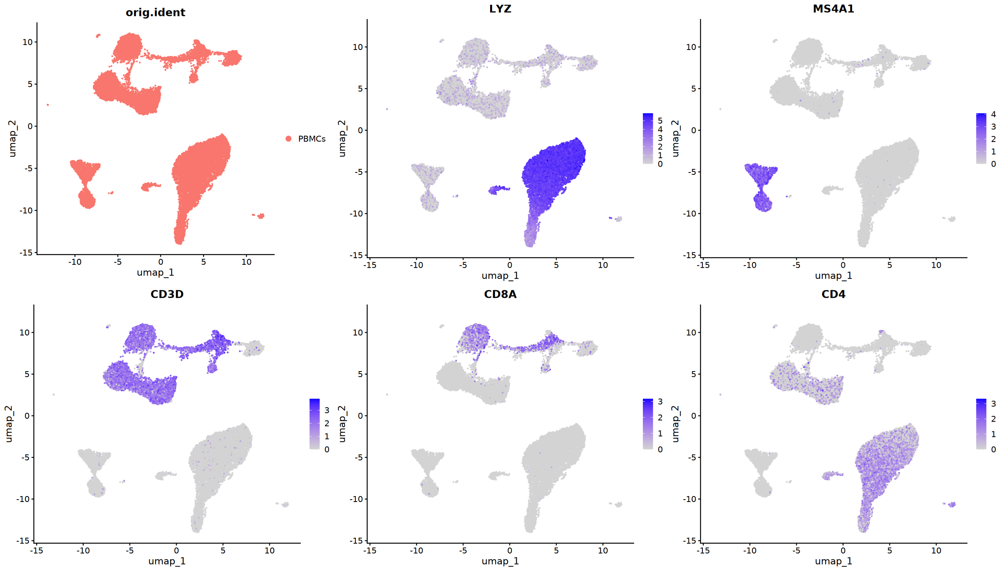

In [40]:
geneset <- c("LYZ", "MS4A1", "CD3D", "CD8A", "CD4")
p1 <- DimPlot(
    sc.temp, reduction = "umap", group.by = "orig.ident")
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", features = geneset,
    combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 3)

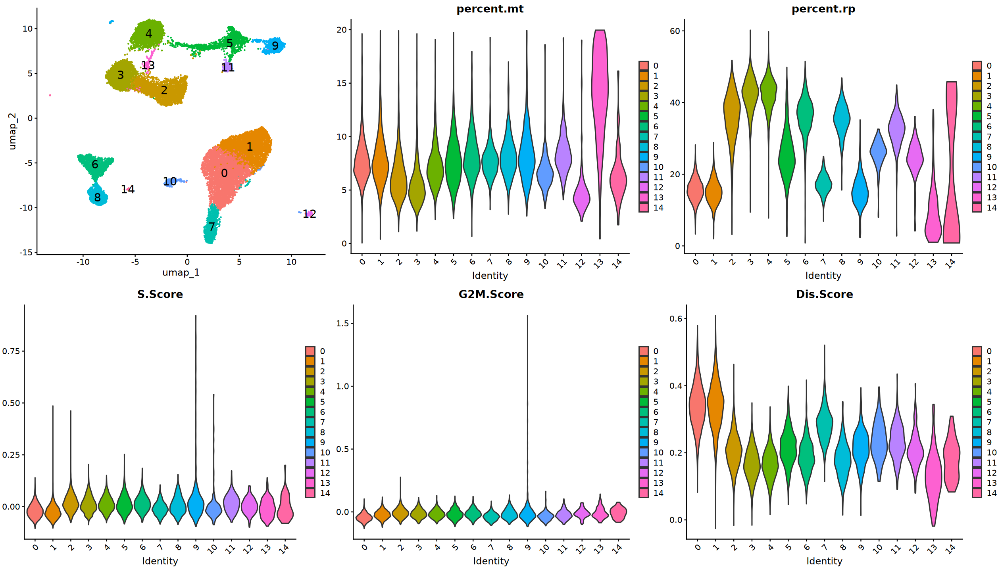

In [41]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- VlnPlot(
    sc.temp, features = c("percent.mt", "percent.rp"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)
p3 <- VlnPlot(
    sc.temp, features = c("S.Score", "G2M.Score", "Dis.Score"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2, p3), ncol = 3)

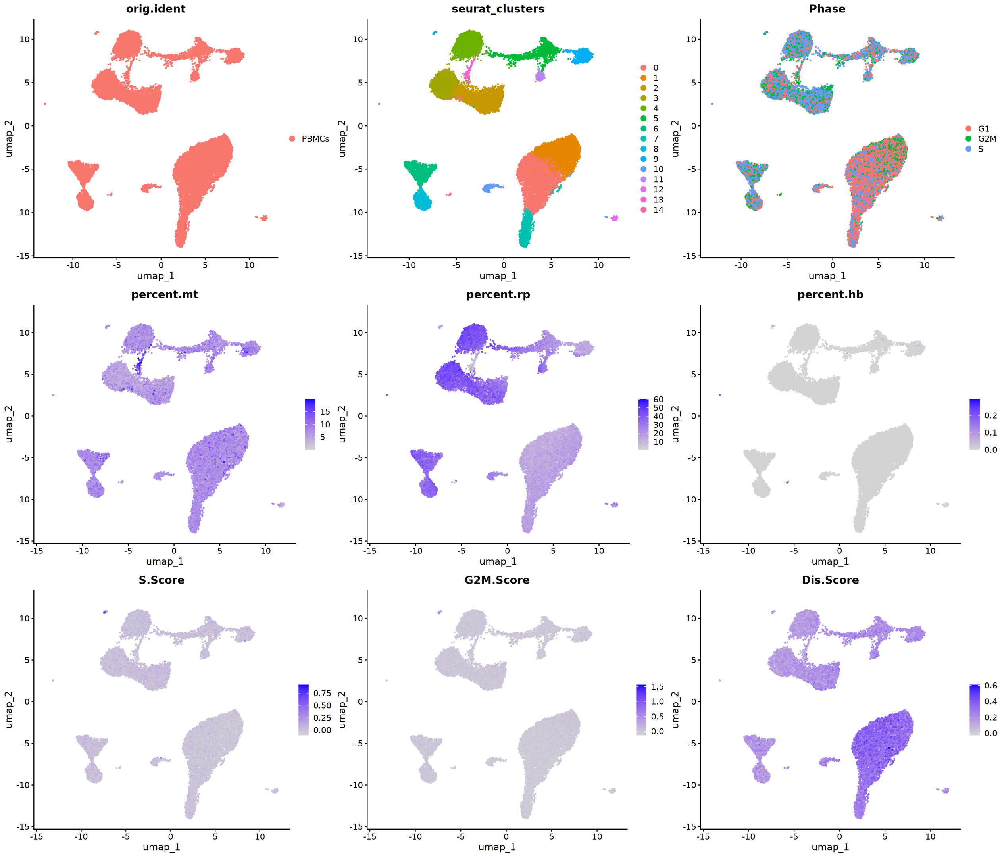

In [42]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", combine = FALSE,
    group.by = c("orig.ident", "seurat_clusters", "Phase"))
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2), ncol = 3)

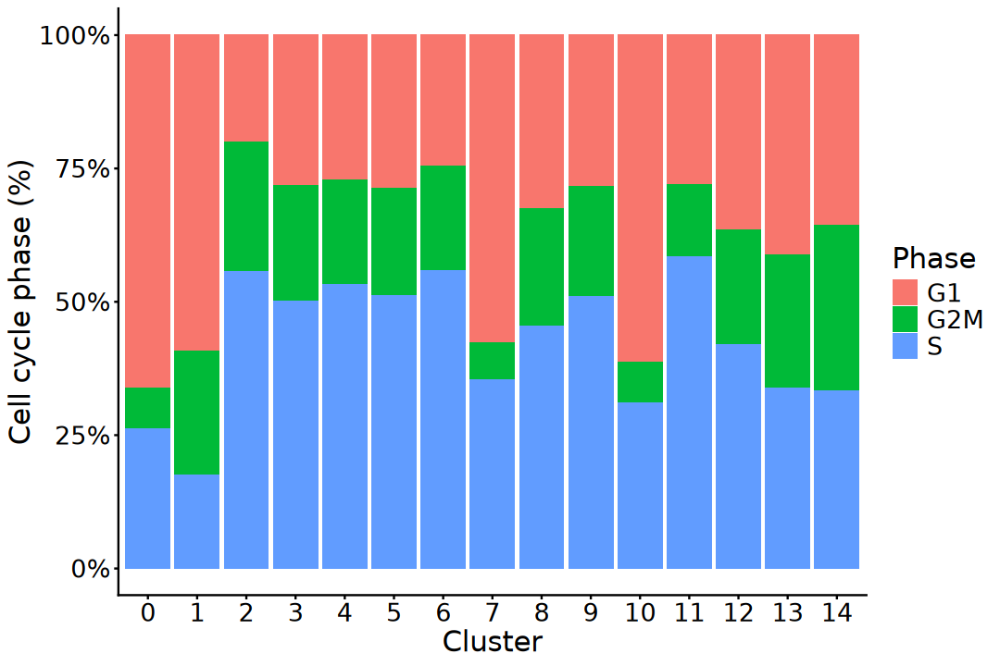

In [43]:
options(repr.plot.width = 9, repr.plot.height = 6)
table(sc.temp$seurat_clusters, sc.temp$Phase) |> 
    as.data.frame() |>
    ggplot(aes(x = Var1, y = Freq, fill = Var2)) +
        geom_bar(stat = "identity", position = "fill") +
        scale_y_continuous(labels = scales::percent_format()) +
        labs(x = "Cluster", y = "Cell cycle phase (%)", 
             fill = "Phase") +
        theme_classic() + 
        theme(axis.title = element_text(size = 18),
              axis.text = element_text(size = 16),
              legend.title = element_text(size = 18),
              legend.text = element_text(size = 16))

In [44]:
pca <- Embeddings(sc.temp, "pca")[, 1:10]

vars <- c("nCount_RNA", "percent.mt", "percent.rp", "percent.hb", 
          "S.Score", "G2M.Score", "Dis.Score")

cors <- sapply(vars, function(v) {
    apply(pca, 2, cor, y = sc.temp[[v]], method = "pearson")
}) |> t()

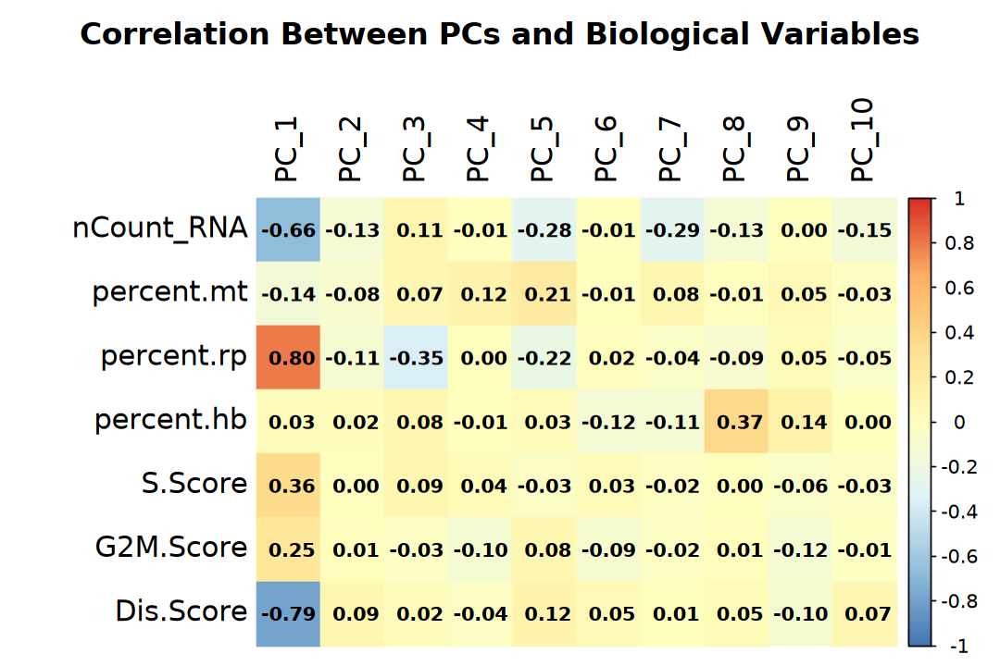

In [45]:
options(repr.plot.width = 9, repr.plot.height = 6)

gradient_colors <- colorRampPalette(
    c("#4575B4", "#91BFDB", "#E0F3F8", "#FFFFBF", 
      "#FEE090", "#FDAE61", "#D73027"))(200)

corrplot::corrplot(cors, method = "color",
                   col = gradient_colors, cl.cex = 1, 
                   col.lim = c(-1, 1),
                   title = "Correlation Between PCs and Biological Variables",
                   cex.main = 1.6, col.main = "black",
                   tl.col = "black", tl.cex = 1.5,
                   addCoef.col = "black", number.cex = 1, 
                   is.corr = FALSE, mar = c(0, 0, 3, 0))

# 4. Normalization

In [46]:
scrna <- NormalizeData(scrna, verbose = FALSE) |>
    FindVariableFeatures(nfeatures = 3000, verbose = FALSE) |>
    ScaleData(vars.to.regress = "percent.mt", verbose = FALSE)
scrna

An object of class Seurat 
24018 features across 21334 samples within 1 assay 
Active assay: RNA (24018 features, 3000 variable features)
 3 layers present: counts, data, scale.data

# 5. Linear Dimensionality Reduction

In [47]:
scrna <- RunPCA(scrna, npcs = 50, verbose = FALSE)

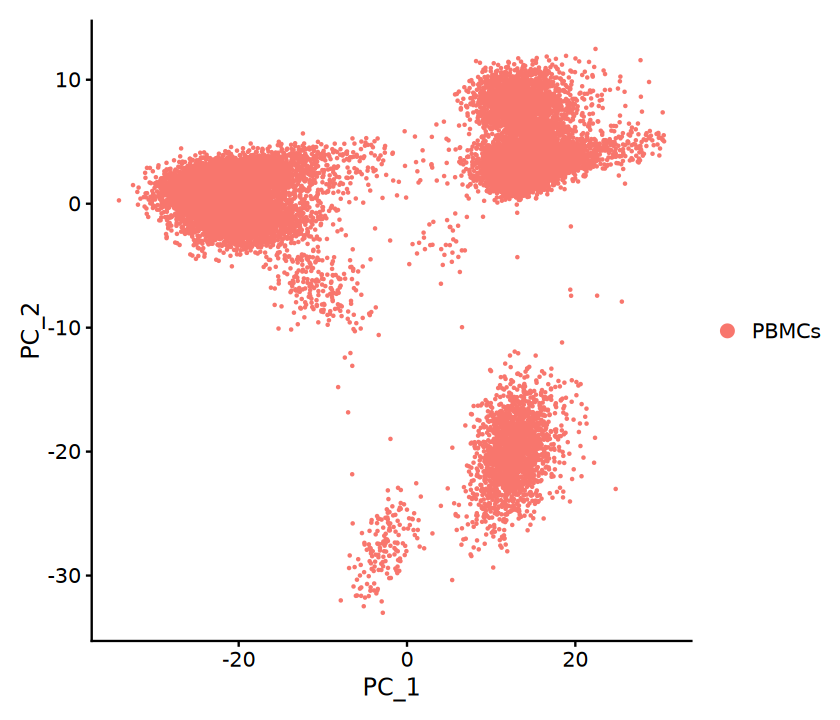

In [48]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(scrna, reduction = "pca")

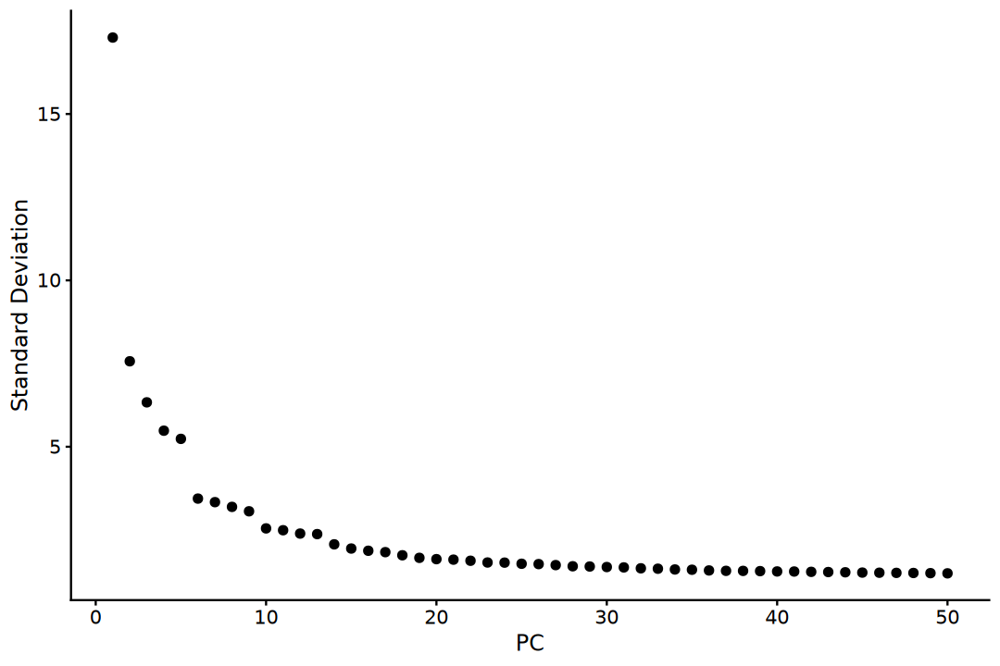

In [49]:
# Elbow plot
options(repr.plot.width = 9, repr.plot.height = 6)
ElbowPlot(scrna, ndims = 50)

In [50]:
# Estimating PCA dimensionality
pca_var <- scrna@reductions$pca@stdev ^ 2
pca_con <- pca_var / sum(pca_var)
nPCs <- which(cumsum(pca_con) > 0.9 & pca_con < 0.05)[1]
print(nPCs)

[1] 18


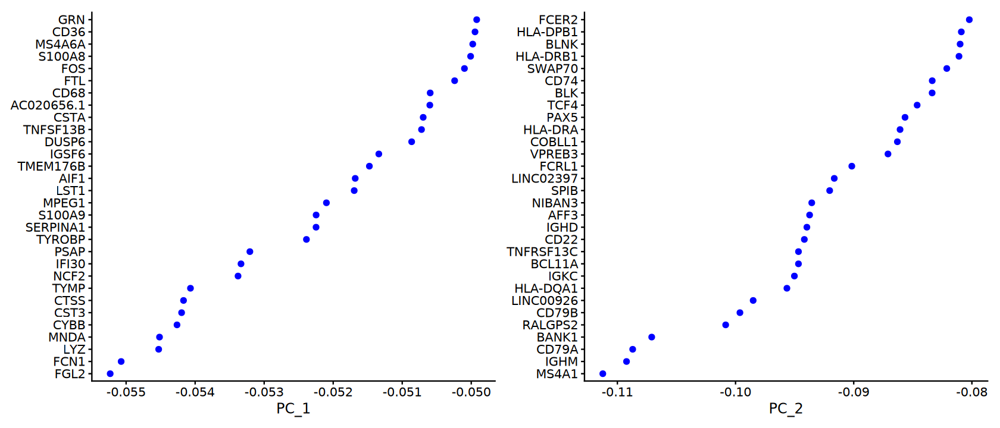

In [51]:
# Gene information
options(repr.plot.width = 14, repr.plot.height = 6)
VizDimLoadings(scrna, dims = 1:2, reduction = "pca", ncol = 2)

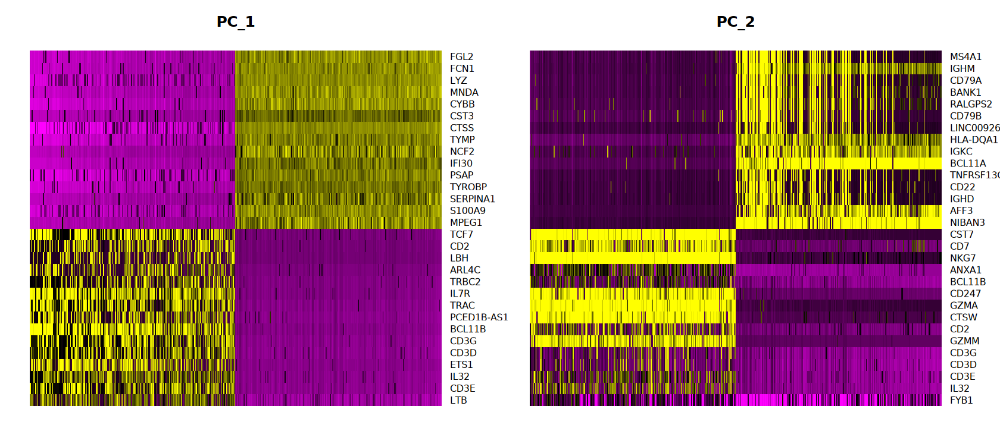

In [52]:
options(repr.plot.width = 14, repr.plot.height = 6)
DimHeatmap(scrna, dims = 1:2, cells = 500, balanced = TRUE)

In [53]:
source("R/compare_npcs_clustering.R")

In [54]:
plots <- compare_npcs_clustering(
    scrna, reduction = "pca", method = "umap")

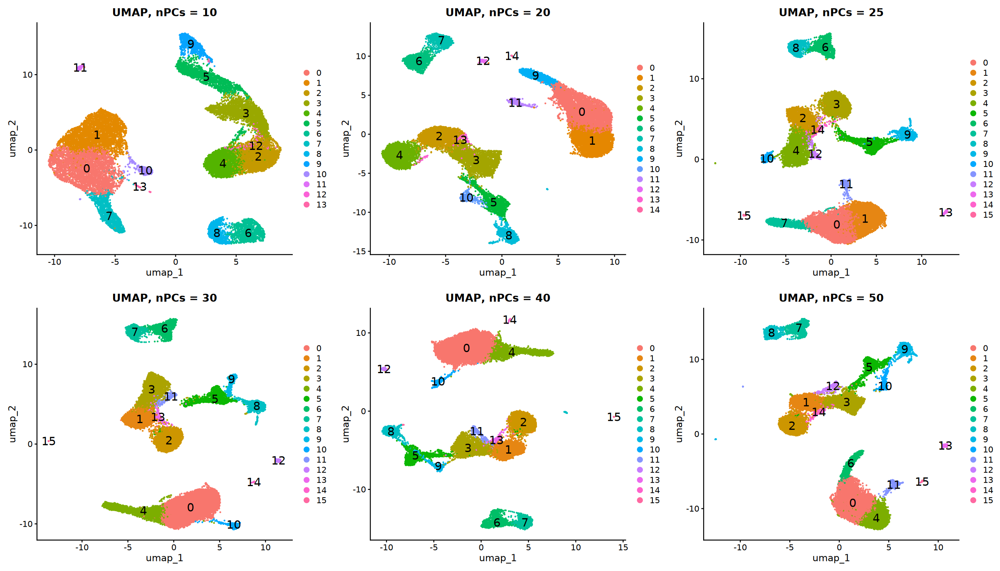

In [55]:
options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = plots, ncol = 3)

In [56]:
nPCs <- 30

# 6. Integration (Skip)

# 7. Neighborhood Graph Construction

In [57]:
scrna <- FindNeighbors(
    scrna, reduction = "pca", k.param = 20, 
    dims = 1:nPCs, verbose = FALSE)

# 8. Non-linear Dimensionality Reduction

In [58]:
scrna <- RunUMAP(
    scrna, dims = 1:nPCs, reduction = "pca", 
    verbose = FALSE)

In [59]:
scrna <- RunTSNE(
    scrna, dims = 1:nPCs, reduction = "pca", 
    verbose = FALSE)

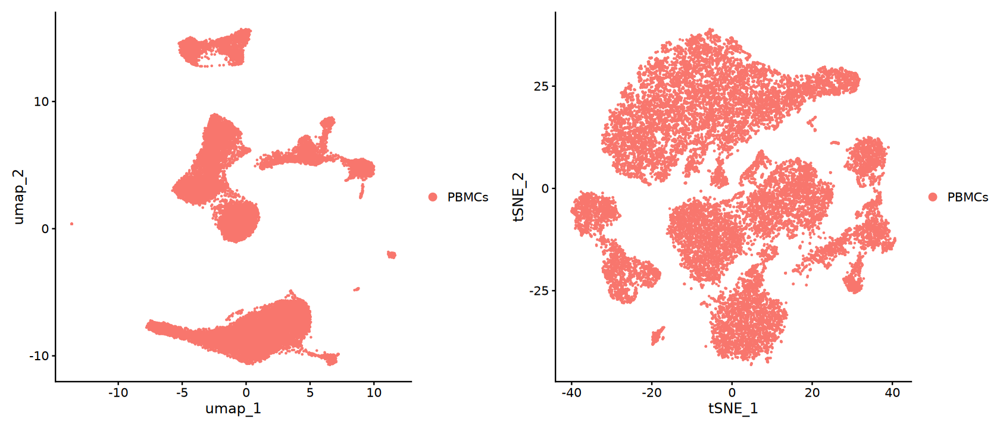

In [60]:
p1 <- DimPlot(scrna, reduction = "umap")
p2 <- DimPlot(scrna, reduction = "tsne")

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

# 9. Clustering

## 1). Resolution Tuning

In [61]:
source("R/scan_clustering_resolution.R")

In [62]:
cluster_list <- scan_clustering_resolution(
    scrna, reduction = "pca", dims = nPCs,
    resolution = seq(0.1, 0.9, 0.1), assess = FALSE)

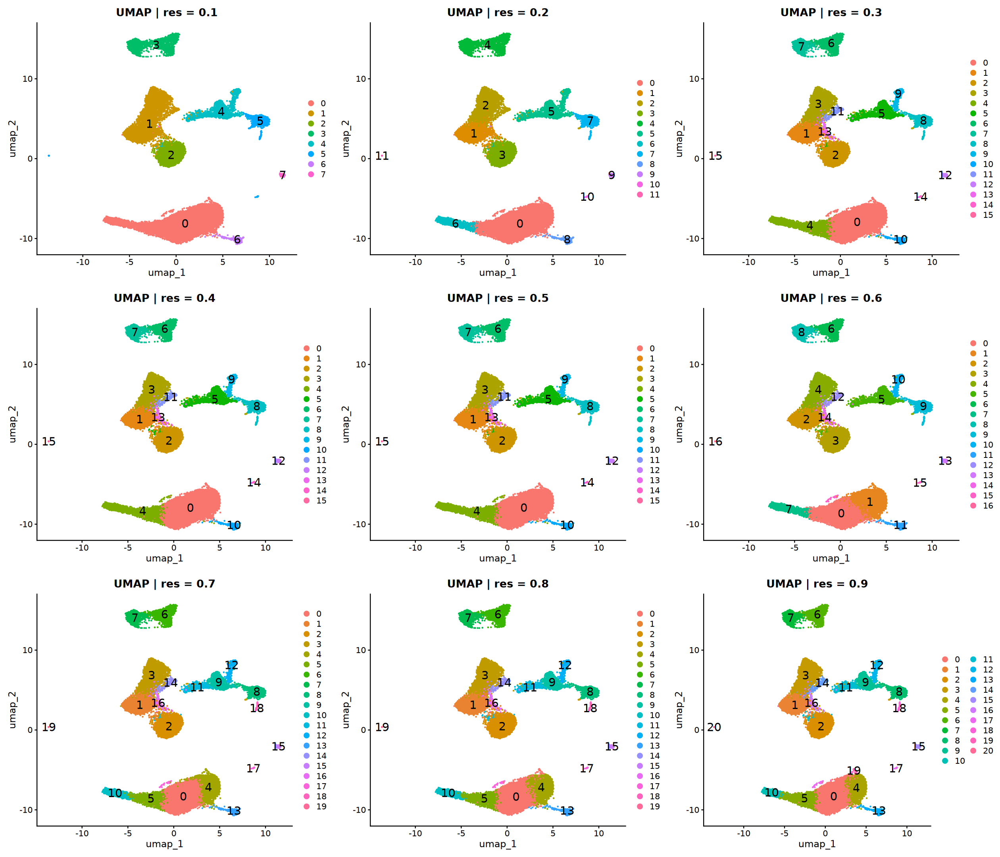

In [63]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = cluster_list$umap, ncol = 3)

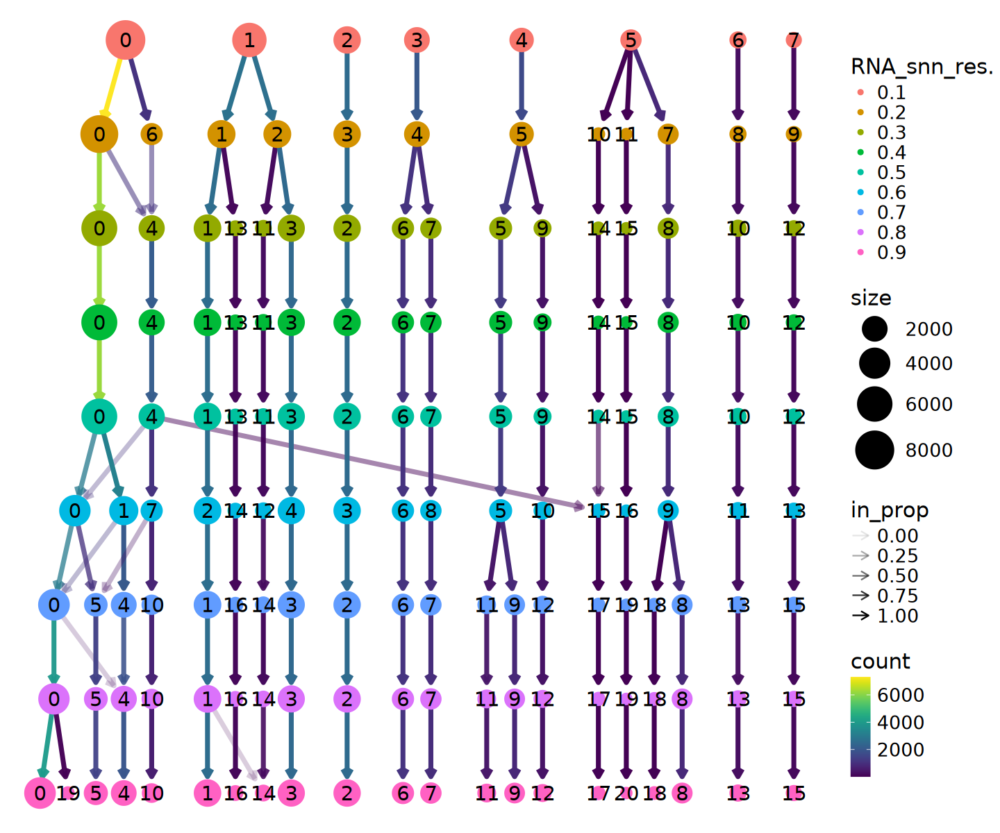

In [64]:
options(repr.plot.width = 12, repr.plot.height = 10)
cluster_list$clustree

In [65]:
scrna <- FindClusters(
    scrna, resolution = 0.5, verbose = FALSE)

## 2). Embedding Visualization

In [66]:
# n.neighbors 5 ~ 50, 30
# min.dist 0.001 ~ 0.5, 0.3
plot_umap_params <- function(obj, dims = 10, nn = 30, md = 0.3) {    
    RunUMAP(obj, dims = 1:dims, reduction = "pca", 
            n.neighbors = nn, min.dist = md, verbose = FALSE) |>
    DimPlot(reduction = "umap", group.by = "seurat_clusters",
            label = TRUE, label.size = 6, repel = FALSE) +
        ggtitle(paste0("n.neighbors = ", nn, "\nmin.dist = ", md))
}

In [67]:
p1 <- lapply(
    c(10, 30, 50), plot_umap_params, 
    obj = scrna, dims = nPCs, md = 0.3)
p2 <- lapply(
    c(0.01, 0.3, 0.5), plot_umap_params, 
    obj = scrna, dims = nPCs, nn = 30)

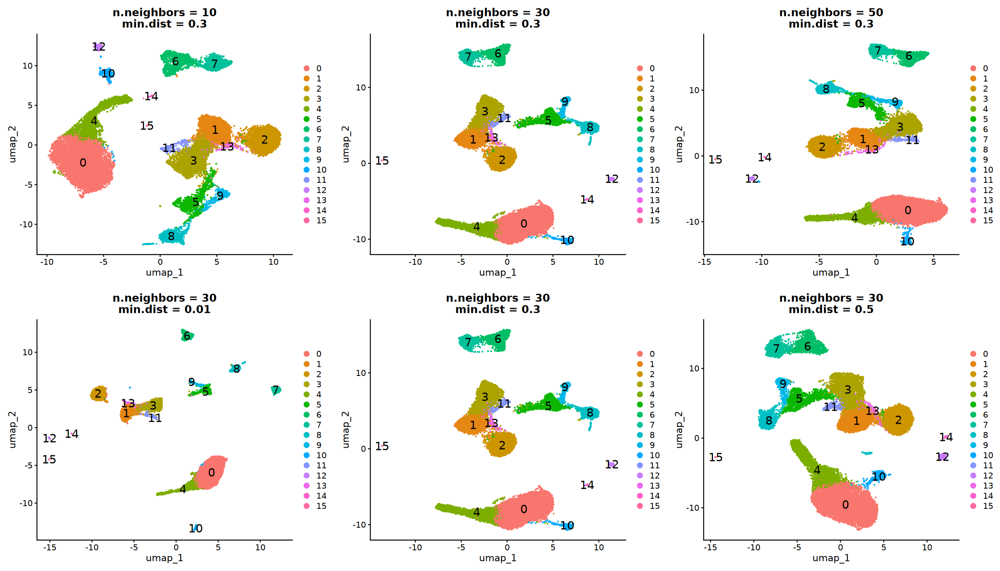

In [68]:
options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plot_grid(plotlist = p1, ncol = 3),
          plot_grid(plotlist = p2, ncol = 3), ncol = 1)

In [69]:
# perplexity 5 ~ 50, 30
plot_tsne_params <- function(obj, dims = 10, perplexity = 30) {    
    RunTSNE(obj, dims = 1:dims, reduction = "pca", 
            perplexity = perplexity, verbose = FALSE) |>
    DimPlot(reduction = "tsne", group.by = "seurat_clusters",
            label = TRUE, label.size = 6, repel = FALSE) +
        ggtitle(paste0("perplexity = ", perplexity))
}

In [70]:
p1 <- lapply(
    c(10, 30, 50), plot_tsne_params,
    obj = scrna, dims = nPCs)

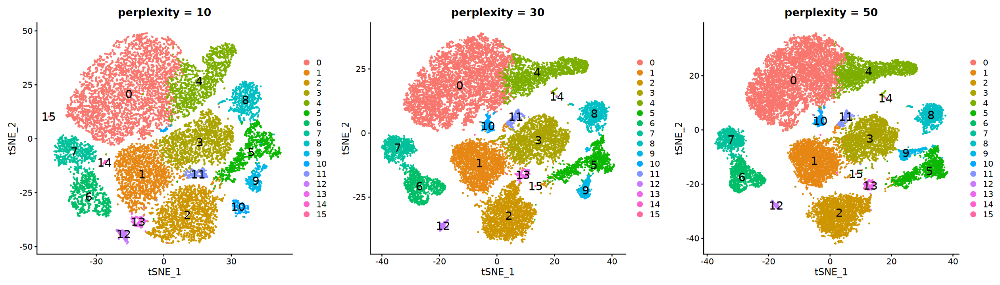

In [71]:
options(repr.plot.width = 21, repr.plot.height = 6)
plot_grid(plotlist = p1, ncol = 3)

In [72]:
scrna <- RunUMAP(
    scrna, dims = seq_len(nPCs), reduction = "pca",
    n.neighbors = 30, min.dist = 0.3, verbose = FALSE)

In [73]:
scrna <- RunTSNE(
    scrna, dims = seq_len(nPCs), reduction = "pca", 
    perplexity = 30, verbose = FALSE)

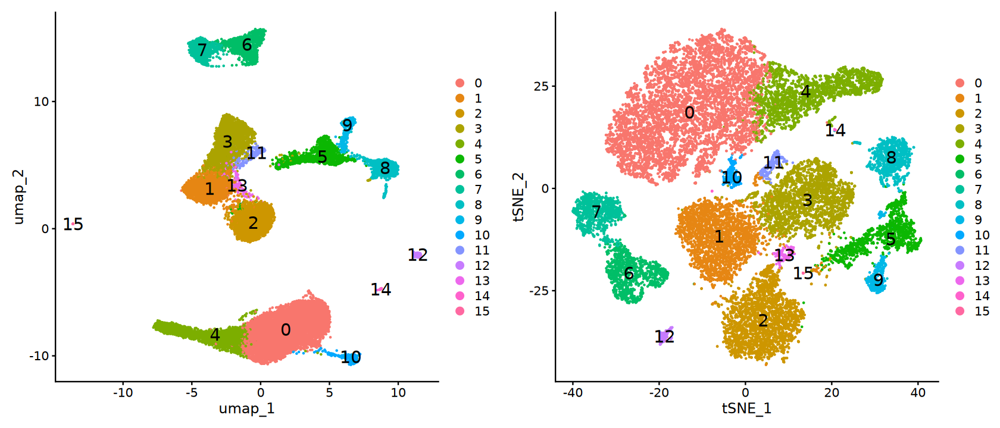

In [74]:
p1 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, 
    label.size = 6, repel = FALSE)
p2 <- DimPlot(
    scrna, reduction = "tsne", label = TRUE, 
    label.size = 6, repel = FALSE)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

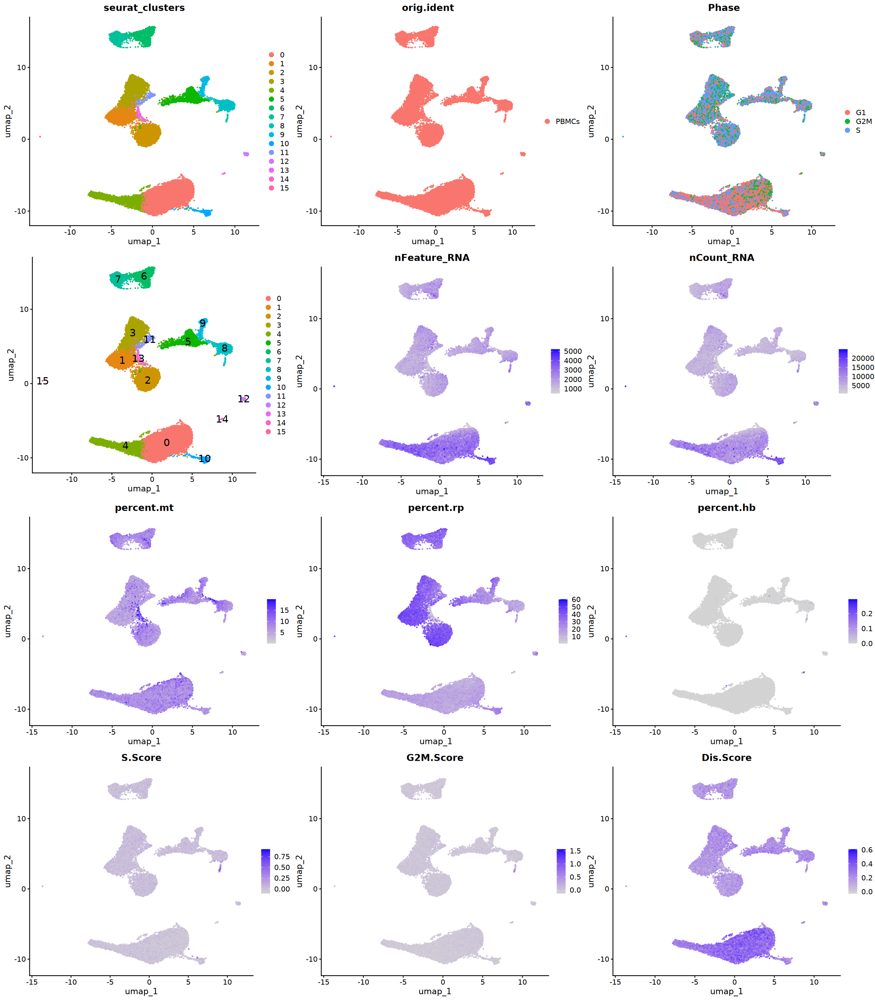

In [75]:
p1 <- DimPlot(
    scrna, reduction = "umap", combine = FALSE,
    group.by = c("seurat_clusters", "orig.ident", "Phase"))
p2 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, 
    label.size = 6)
p3 <- FeaturePlot(
    scrna, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"))
p4 <- FeaturePlot(
    scrna, reduction = "umap", combine = FALSE,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 24)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3)

In [76]:
scrna

An object of class Seurat 
24018 features across 21334 samples within 1 assay 
Active assay: RNA (24018 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 3 dimensional reductions calculated: pca, umap, tsne

# 10. Cluster Biomarkers

In [77]:
sc.markers <- FindAllMarkers(
    scrna, logfc.threshold = log2(1.2), min.pct = 0.25, 
    only.pos = TRUE, verbose = FALSE)

In [78]:
sc.markers.filt <- sc.markers |> 
    filter(p_val_adj < 0.01, 
           avg_log2FC > log2(1.2), 
           pct.1 - pct.2 > 0.2)

In [79]:
sc.markers.filt |> 
    group_by(cluster) |> 
    summarise(length(gene)) |>
    t()

cluster,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
length(gene),1641,65,103,105,1830,108,209,146,182,136,1952,96,1967,33,294,599


In [80]:
top10 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC)

top3 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(3, wt = avg_log2FC)

## Visualization

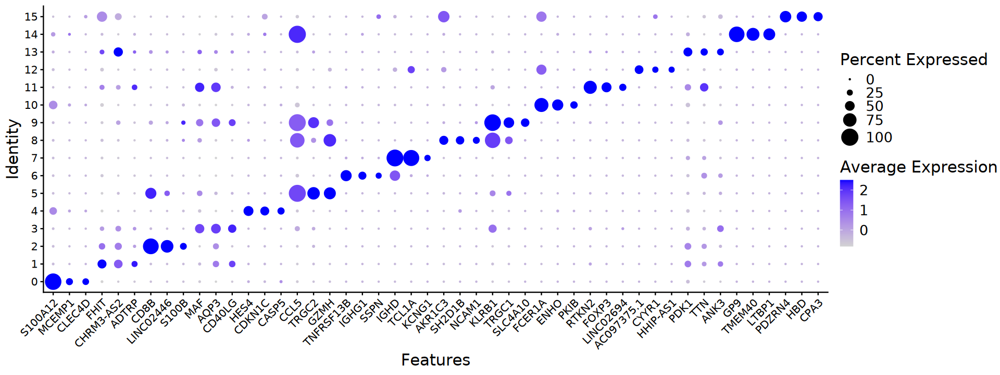

In [81]:
options(repr.plot.width = 16, repr.plot.height = 6)
DotPlot(scrna, features = unique(top3$gene), dot.scale = 8) + 
    RotatedAxis() + 
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

# 11. Cell-type Annotation

## a). Automatic

In [82]:
suppressPackageStartupMessages(library(SingleR))

In [83]:
ref_pbmc <- file.path(
    "~/data1/single_cell_dataset/PBMCs/Hs_PBMC_GSE164378", 
    "matrix", "RNA_3P", "RNA") |>
    Read10X()

In [84]:
ref_metadata <- file.path(
    "~/data1/single_cell_dataset/PBMCs/Hs_PBMC_GSE164378", 
    "GSE164378_sc.meta.data_3P.csv.gz") |>
    read.csv(header = TRUE, row.names = 1) |>
    select(celltype.l1, celltype.l2, celltype.l3)

In [85]:
ref_pbmc <- SingleCellExperiment(
    list(counts = ref_pbmc), 
    colData = ref_metadata)

ref_pbmc <- scuttle::logNormCounts(ref_pbmc)

ref_pbmc

class: SingleCellExperiment 
dim: 33538 161764 
metadata(0):
assays(2): counts logcounts
rownames(33538): MIR1302-2HG FAM138A ... AC213203.1 FAM231C
rowData names(0):
colnames(161764): L1_AAACCCAAGAAACTCA L1_AAACCCAAGACATACA ...
  E2L8_TTTGTTGGTTGGCTAT E2L8_TTTGTTGTCTCATGGA
colData names(4): celltype.l1 celltype.l2 celltype.l3 sizeFactor
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):

In [86]:
# SingleR performs the prediction of celltypes for each cluster
celltype.SingleR <- LayerData(
    scrna, assay = "RNA", layer = "data") |>
    SingleR(ref = ref_pbmc, labels = ref_pbmc$celltype.l1, 
            clusters = scrna$seurat_clusters,
            de.method = "wilcox")

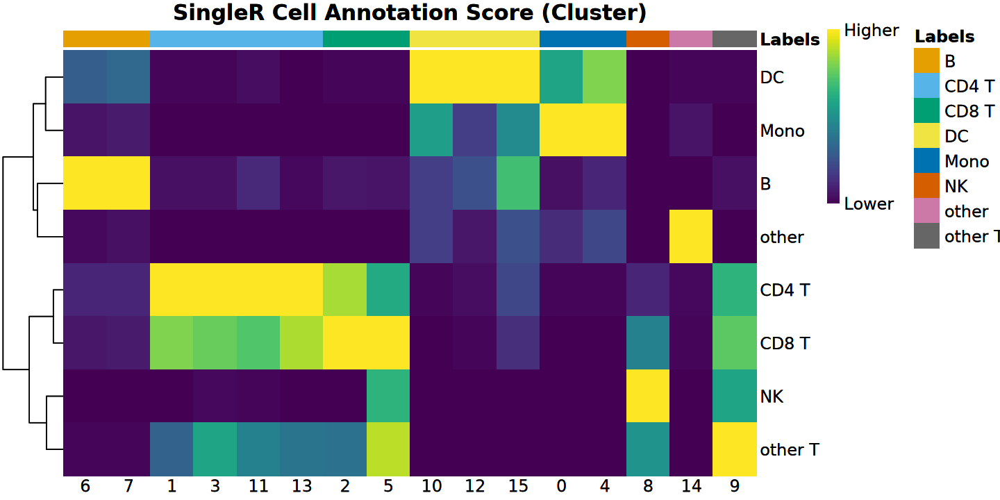

In [87]:
options(repr.plot.width = 12, repr.plot.height = 6)
plotScoreHeatmap(
    celltype.SingleR, show_colnames = TRUE, 
    main = "SingleR Cell Annotation Score (Cluster)",
    angle_col = 0, fontsize = 14)

In [88]:
scrna$celltype.SingleR.l1 <- 
    celltype.SingleR$labels[scrna$seurat_clusters]

In [89]:
# SingleR performs the prediction of celltypes for each cluster
celltype.SingleR <- LayerData(
    scrna, assay = "RNA", layer = "data") |>
    SingleR(ref = ref_pbmc, labels = ref_pbmc$celltype.l2, 
            clusters = scrna$seurat_clusters,
            de.method = "wilcox")

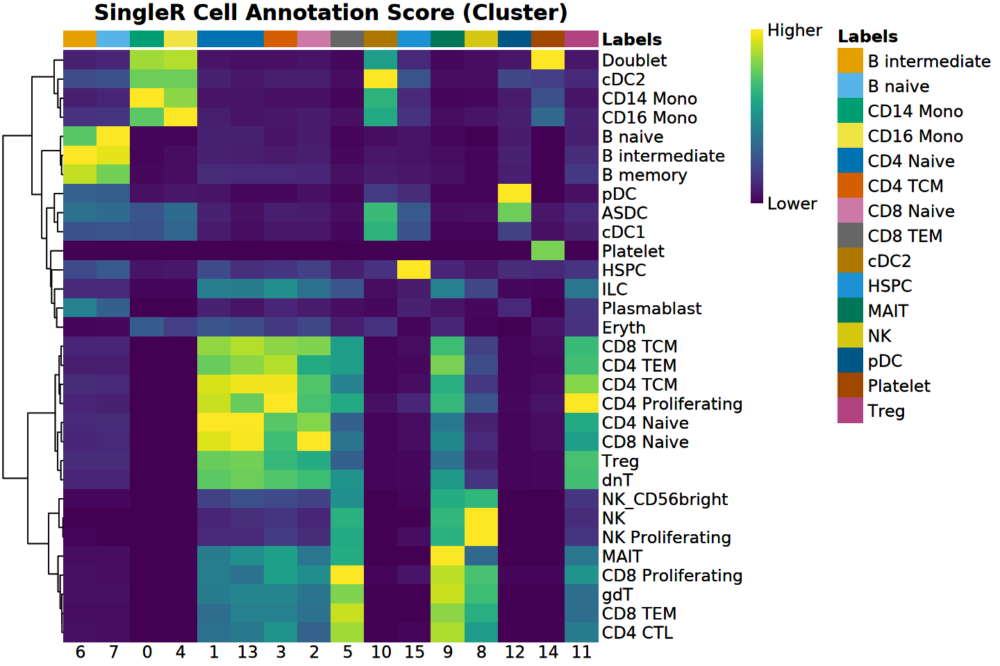

In [90]:
options(repr.plot.width = 12, repr.plot.height = 8)
plotScoreHeatmap(
    celltype.SingleR, show_colnames = TRUE, 
    main = "SingleR Cell Annotation Score (Cluster)",
    angle_col = 0, fontsize = 14)

In [91]:
scrna$celltype.SingleR.l2 <- 
    celltype.SingleR$labels[scrna$seurat_clusters]

In [92]:
# SingleR performs the prediction of celltypes for each cluster
celltype.SingleR <- LayerData(
    scrna, assay = "RNA", layer = "data") |>
    SingleR(ref = ref_pbmc, labels = ref_pbmc$celltype.l3, 
            clusters = scrna$seurat_clusters,
            de.method = "wilcox")

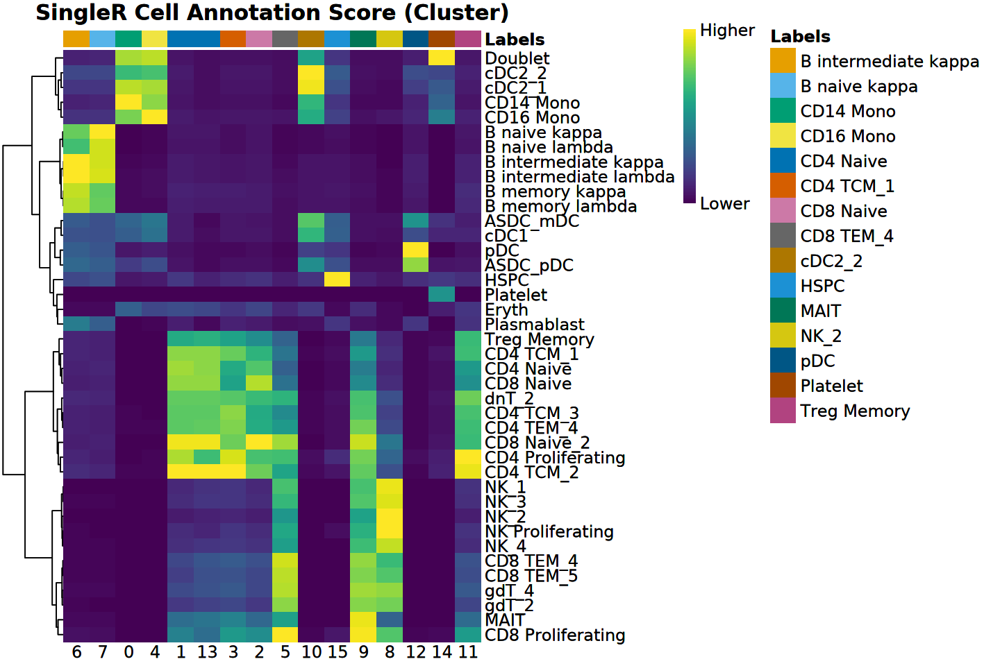

In [93]:
options(repr.plot.width = 12, repr.plot.height = 8)
plotScoreHeatmap(
    celltype.SingleR, show_colnames = TRUE, 
    main = "SingleR Cell Annotation Score (Cluster)",
    angle_col = 0, fontsize = 14)

In [94]:
scrna$celltype.SingleR.l3 <- 
    celltype.SingleR$labels[scrna$seurat_clusters]

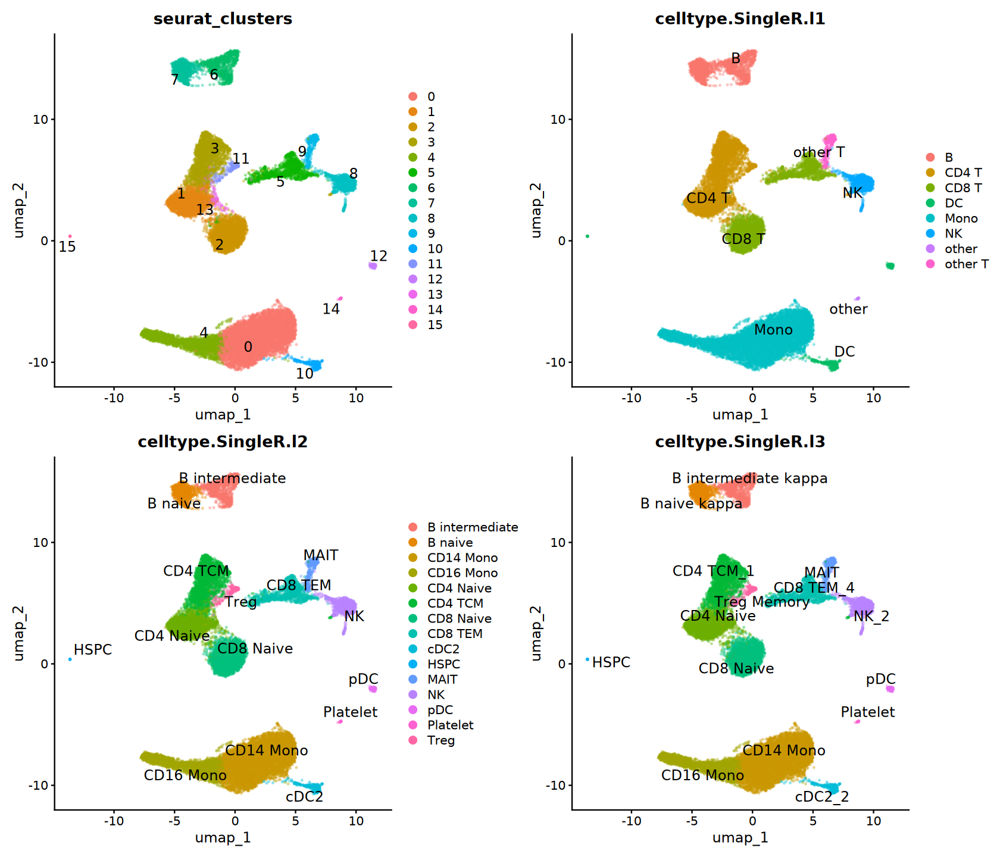

In [95]:
options(repr.plot.width = 14, repr.plot.height = 12)
DimPlot(scrna, reduction = "umap", 
        group.by = c("seurat_clusters", "celltype.SingleR.l1", 
                     "celltype.SingleR.l2", "celltype.SingleR.l3"), 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.3,  alpha = 0.3) + 
    NoLegend()

## b). Manual

In [96]:
gene_list <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC) |>
    summarise(genes = paste0('"', gene, '"', collapse = ", ")) |>
    mutate(out = paste0("cluster_", cluster, ": ", genes)) |> 
    pull(out)

In [97]:
gene_list |> cat(sep = "\n")

cluster_0: "S100A12", "S100A8", "CYP1B1", "S1PR3", "STEAP4", "THBS1", "CRISPLD2", "MCEMP1", "CLEC4D", "MARC1"
cluster_1: "CCR7", "LEF1", "MAL", "TRABD2A", "FHIT", "TRAT1", "CHRM3-AS2", "ADTRP", "CD40LG", "LINC01550"
cluster_2: "CD8B", "KLRK1", "CD8A", "LINC02446", "NELL2", "LRRN3", "THEMIS", "S100B", "PASK", "SCGB3A1"
cluster_3: "INPP4B", "TRAT1", "GPR183", "MAF", "AQP3", "CD40LG", "CD28", "GATA3", "SLAMF1", "AP3M2"
cluster_4: "FCGR3A", "HES4", "BATF3", "CTSL", "CDKN1C", "SASH1", "CASP5", "AC064805.1", "NEURL1", "MS4A4A"
cluster_5: "CCL5", "KLRG1", "TRGC2", "GZMH", "LINC01871", "GZMK", "A2M-AS1", "FCRL6", "TIGIT", "EOMES"
cluster_6: "TNFRSF13B", "CD24", "OSBPL10", "LINC01857", "IGHG1", "CPNE5", "LINC01781", "IGHG2", "IGHG3", "SSPN"
cluster_7: "IGHD", "TCL1A", "LINC00926", "FCER2", "FCRL1", "LINC02397", "COL19A1", "PCDH9", "CD200", "KCNG1"
cluster_8: "KLRF1", "SPON2", "CLIC3", "AKR1C3", "SH2D1B", "LINC00299", "NMUR1", "NCAM1", "NCR1", "IL18RAP"
cluster_9: "KLRB1", "KLRG1", "GZMK", "NCR3

Picking joint bandwidth of 0.181

Picking joint bandwidth of 0.0141

Picking joint bandwidth of 0.01

Picking joint bandwidth of 0.0672

Picking joint bandwidth of 0.0329

Picking joint bandwidth of 0.057



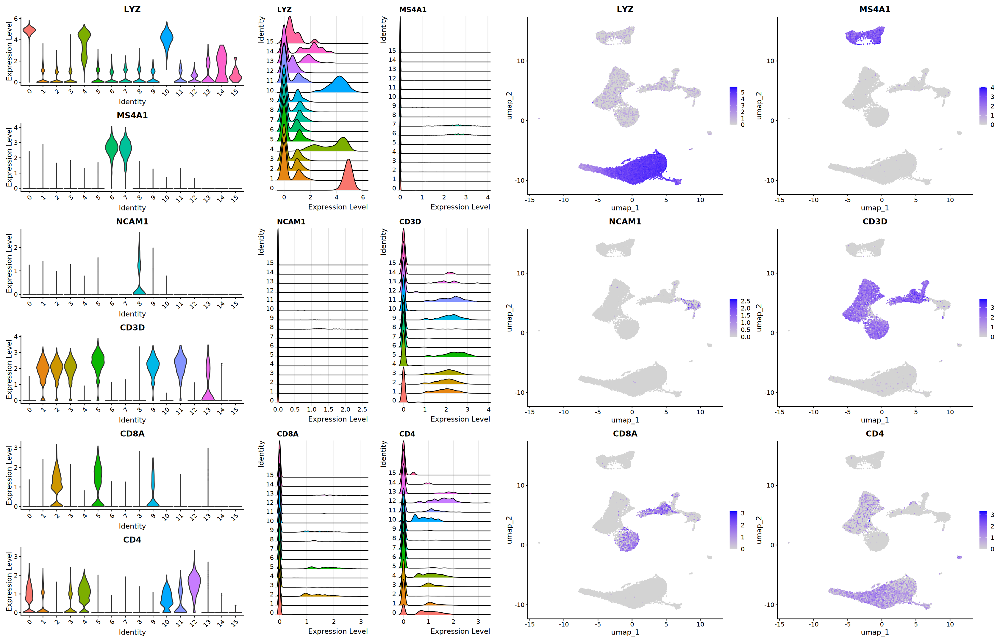

In [98]:
geneset <- c("LYZ", "MS4A1", "NCAM1", "CD3D", "CD8A", "CD4")
p1 <- VlnPlot(
    scrna, features = geneset, ncol = 1, pt.size = 0)
p2 <- RidgePlot(
    scrna, features = geneset, ncol = 2)
p3 <- FeaturePlot(
    scrna, reduction = "umap", features = geneset, ncol = 2)

options(repr.plot.width = 28, repr.plot.height = 18)
plot_grid(p1, p2, p3, ncol = 3, rel_widths = c(1, 1, 2))

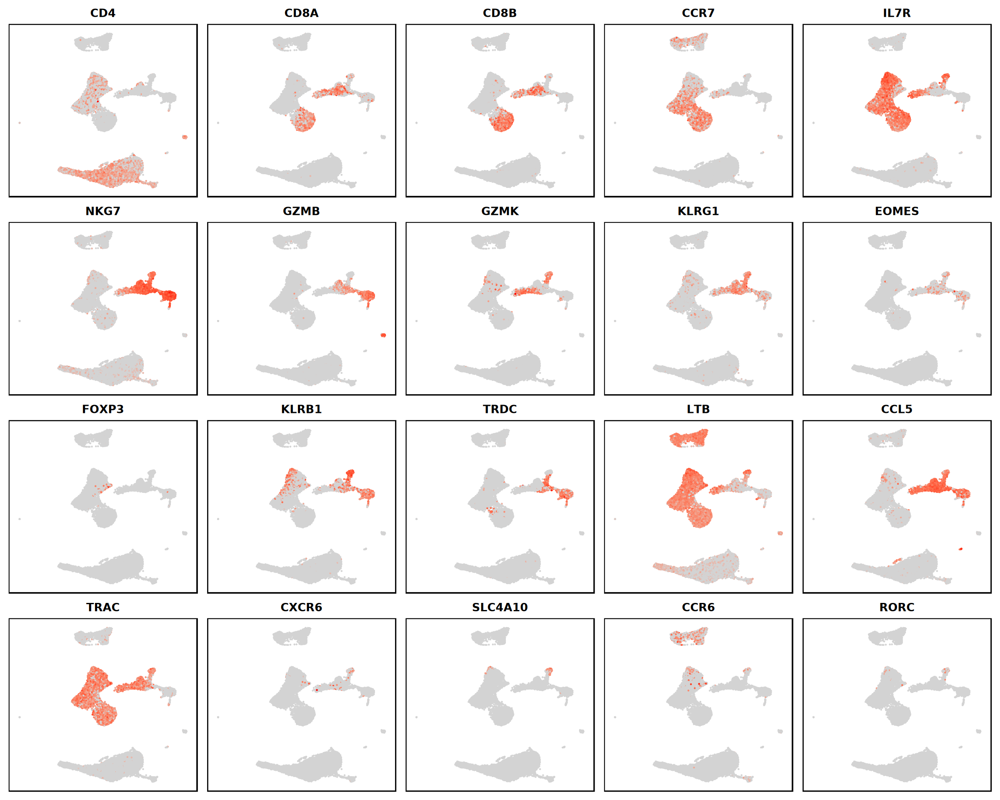

In [99]:
geneset <- c("CD4", "CD8A", "CD8B", "CCR7", "IL7R", 
             "NKG7", "GZMB", "GZMK", "KLRG1", "EOMES", 
             "FOXP3", "KLRB1", "TRDC", "LTB", "CCL5",
             "TRAC", "CXCR6", "SLC4A10", "CCR6", "RORC")

options(repr.plot.width = 20, repr.plot.height = 16)
FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

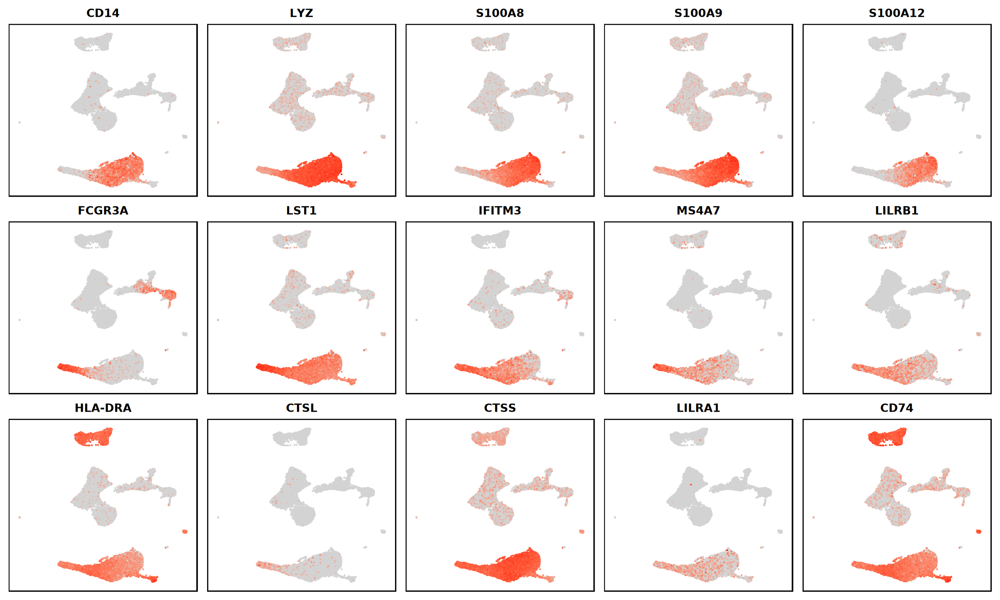

In [100]:
# Classical monocytes: "CD14", "LYZ", "S100A8", "S100A9", "S100A12"
# Non-classical monocytes: "FCGR3A", "LST1", "IFITM3", "MS4A7", "LILRB1"
# Intermediate monocytes: "CD14", "FCGR3A", "HLA-DRA", "HLA-DPB1", "CTSL", "CTSS", "LILRA1", "CD74"

geneset <- c("CD14", "LYZ", "S100A8", "S100A9", "S100A12",
             "FCGR3A", "LST1", "IFITM3", "MS4A7", "LILRB1",
             "HLA-DRA", "CTSL", "CTSS", "LILRA1", "CD74")

options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

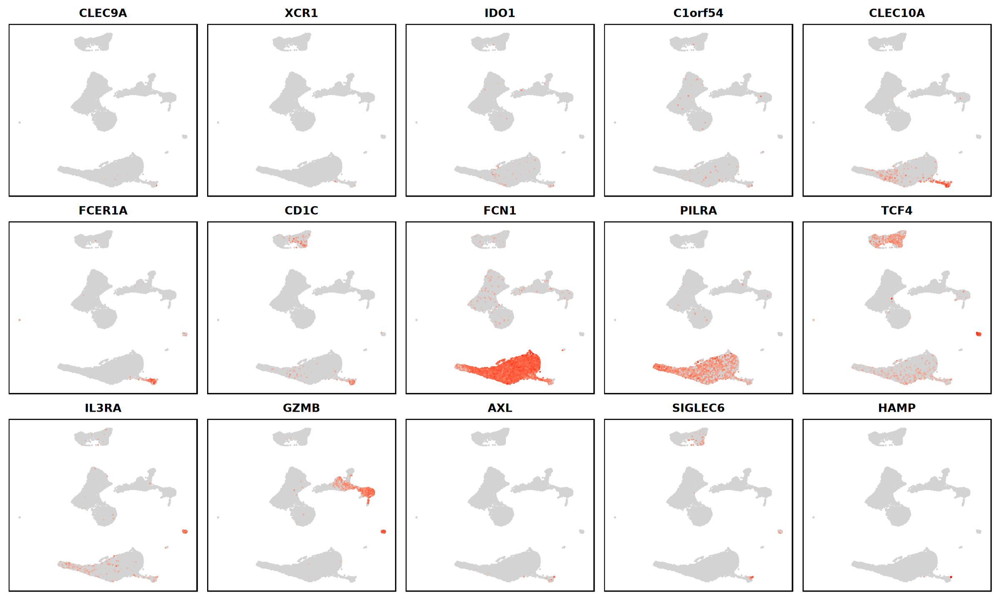

In [101]:
# cDC1: "CLEC9A", "XCR1", "IDO1", "C1orf54"
# cDC2: "CD1C", "FCN1", "PILRA"
# pDC: "GZMB", "TCF4", "IL3RA", "CLEC4C"
# ASDC: "AXL", "SIGLEC6", "HAMP"

geneset <- c("CLEC9A", "XCR1", "IDO1", "C1orf54",
             "CLEC10A", "FCER1A", "CD1C", "FCN1", "PILRA",
             "TCF4", "IL3RA", "GZMB",
             "AXL", "SIGLEC6", "HAMP")

options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

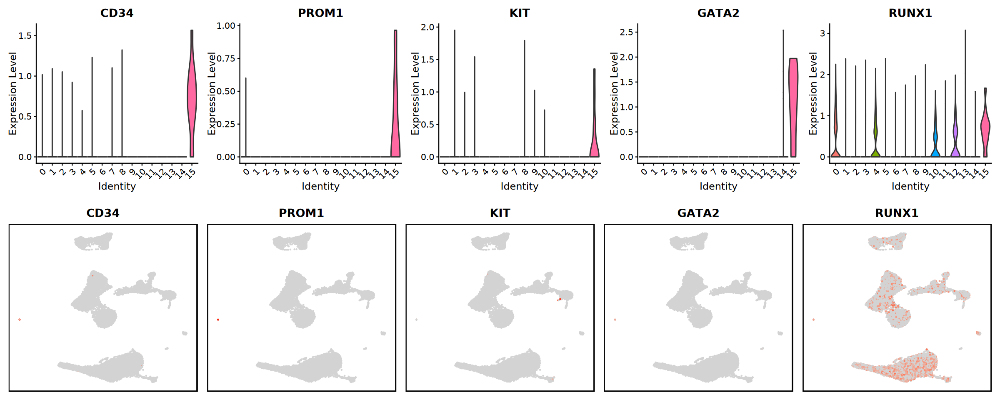

In [102]:
# HSPC
geneset <- c("CD34", "PROM1", "KIT", "GATA2", "RUNX1")

p1 <- VlnPlot(
    scrna, features = geneset, ncol = 5, pt.size = 0)
p2 <- FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

options(repr.plot.width = 20, repr.plot.height = 8)
plot_grid(p1, p2, ncol = 1)

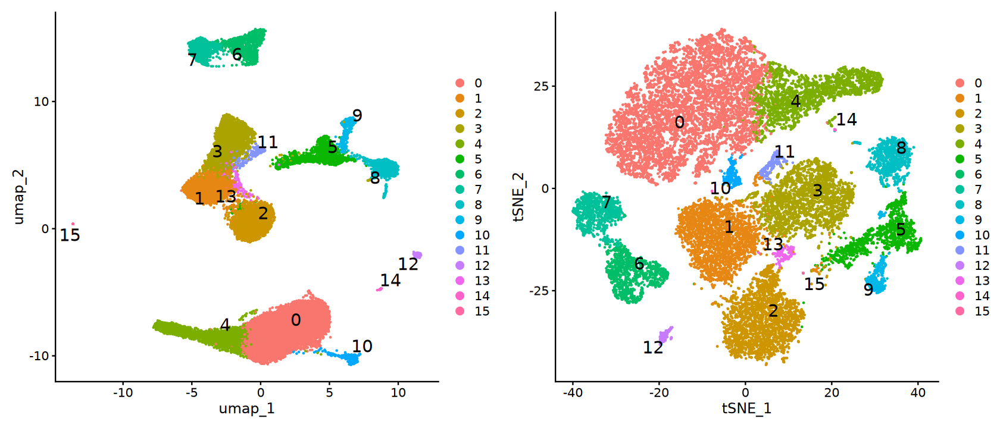

In [103]:
p1 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, 
    label.size = 6, repel = TRUE)
p2 <- DimPlot(
    scrna, reduction = "tsne", label = TRUE, 
    label.size = 6, repel = TRUE)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [104]:
# Cell annotation with ChatGPT assistance
cluster2celltype <- c(
    "0" = "Classical Monocytes", "1" = "Naïve CD4 T", "2" = "Naïve CD8 T",
    "3" = "Activated CD4 T", "4" = "Non-classical Monocytes", "5" = "Cytotoxic CD8 T",
    "6" = "Plasmablast", "7" = "Naive B", "8" = "NK Cells",
    "9" = "MAIT", "10" = "cDC2", "11" = "Treg", 
    "12" = "pDC", "13" = "Activated CD4 T", "14" = "Platelet", "15" = "HSPC")

In [105]:
scrna@meta.data$celltype <- 
    cluster2celltype[as.character(scrna$seurat_clusters)]

scrna <- RenameIdents(scrna, cluster2celltype)

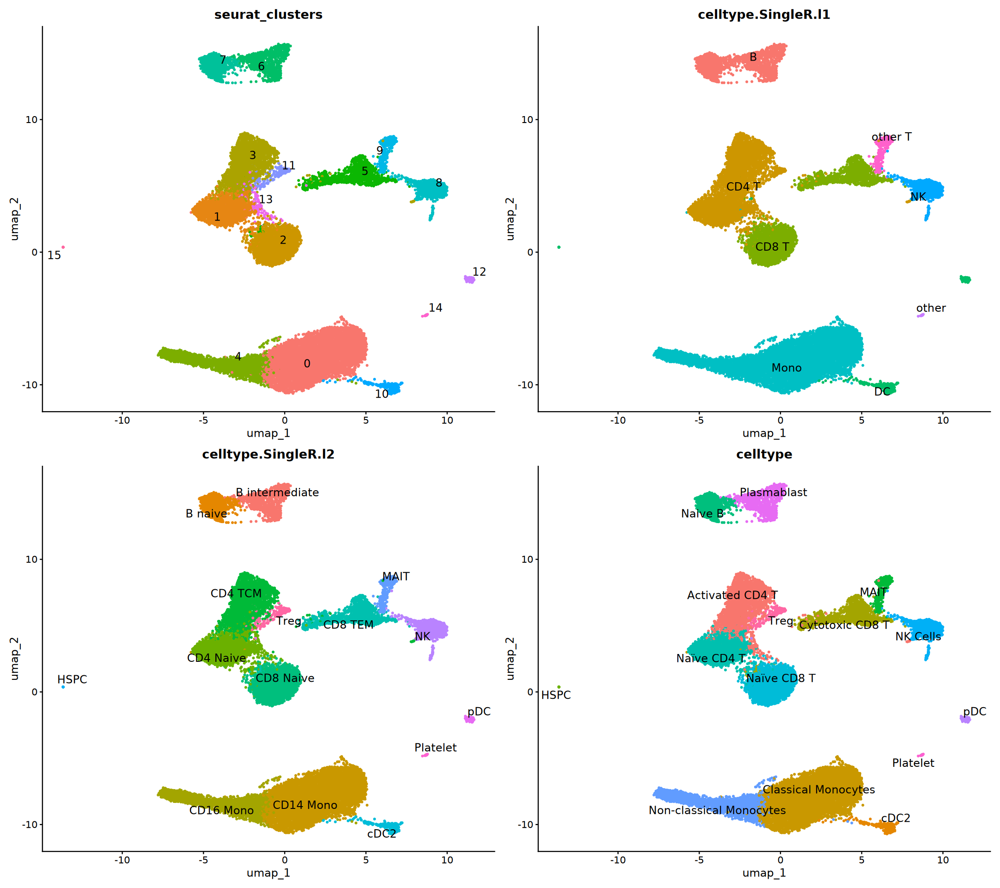

In [106]:
options(repr.plot.width = 18, repr.plot.height = 16)
DimPlot(scrna, reduction = "umap",
        group.by = c("seurat_clusters", "celltype.SingleR.l1", 
                     "celltype.SingleR.l2", "celltype"), 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.5) & 
    NoLegend()

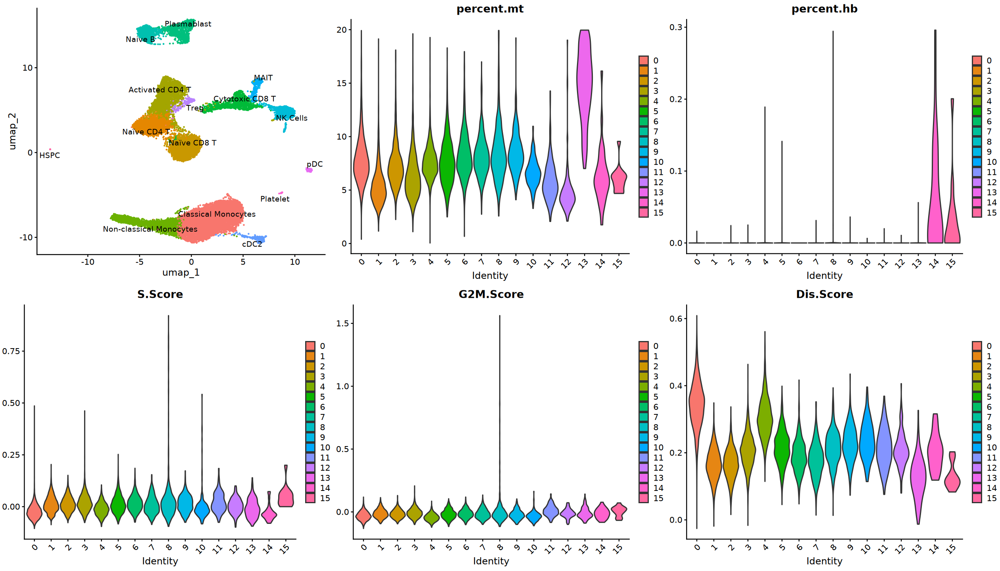

In [107]:
p1 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, 
    label.size = 4, repel = TRUE) & NoLegend()
p2 <- VlnPlot(
    scrna, features = c("percent.mt", "percent.hb"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)
p3 <- VlnPlot(
    scrna, features = c("S.Score", "G2M.Score", "Dis.Score"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2, p3), ncol = 3)

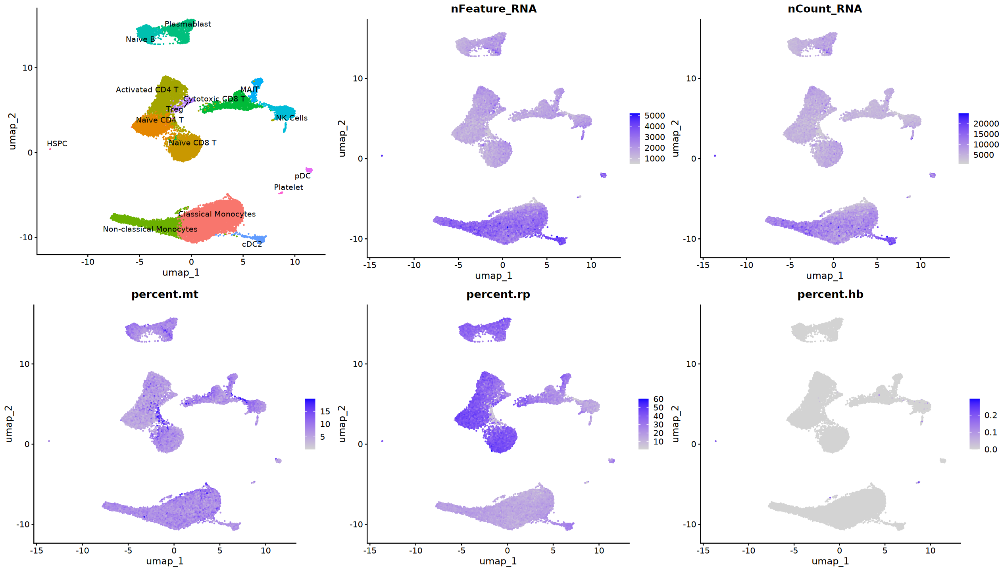

In [108]:
p1 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, 
    label.size = 4, repel = TRUE) & NoLegend()
p2 <- FeaturePlot(
    scrna, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                 "percent.rp", "percent.hb"))

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 3)